# Figure 1 Panel C

Generates barplots of differentially accessible region (DAR) counts at varied timepoints and doses of BAF inhibition. 

*Output: Panel_C.pdf*

# Setup

In [1]:
#load packages
library(tidyverse)
library(RColorBrewer)
library(patchwork)
library(here)
here::i_am("figures/Figure1/PanelC/Panel_C.ipynb")
here()

theme_set(theme_bw() + theme(panel.grid=element_blank()))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/Figure1/PanelC

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



[1] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics"

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         patchwork_1.3.0    RColorBrewer_1.1-3 lubridate_1.9.4   
 [5] forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4        purrr_1.0.2       
 [9] readr_2.1.5        tidyr_1.3.1        tibble_3.2.1       ggplot2_3.5.2     
[13] tidyverse_2.0.0   

loaded via a namespace (an

# Read in data (DAR results)

In [2]:
# Read in BAFinh dose series DAR results
dar_0.01 <- read.delim(
  here("inputs", "DARs", "dose_10nM_DARs.tsv"),
  sep = "\t"
)

dar_0.1 <- read.delim(
  here("inputs", "DARs", "dose_100nM_DARs.tsv"),
  sep = "\t"
)

dar_1 <- read.delim(
  here("inputs", "DARs", "dose_1uM_DARs.tsv"),
  sep = "\t"
)

dar_10 <- read.delim(
  here("inputs", "DARs", "dose_10uM_DARs.tsv"),
  sep = "\t"
)

# Read in BAFinh timecourse series DAR results
dar_0.5h <- read.delim(
  here("inputs", "DARs", "time_0.5h_DARs.tsv"),
  sep = "\t"
)

dar_1h <- read.delim(
  here("inputs", "DARs", "time_1h_DARs.tsv"),
  sep = "\t"
)

dar_2h <- read.delim(
  here("inputs", "DARs", "time_2h_DARs.tsv"),
  sep = "\t"
)

dar_6h <- read.delim(
  here("inputs", "DARs", "time_6h_DARs.tsv"),
  sep = "\t"
)

dar_24h <- read.delim(
  here("inputs", "DARs", "time_24h_DARs.tsv"),
  sep = "\t"
)


# Generate plots

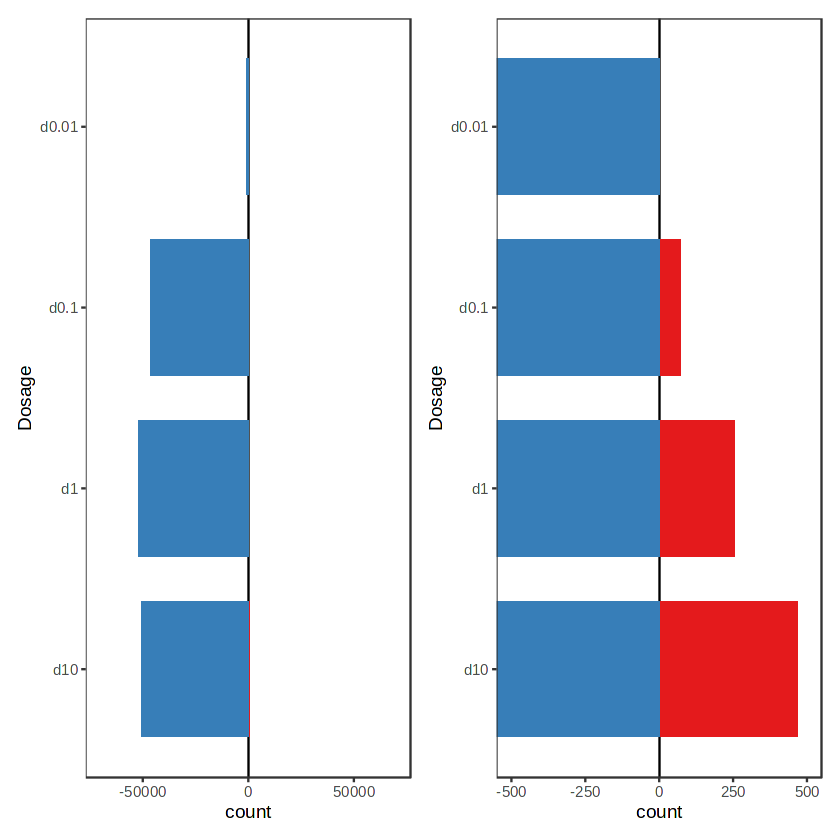

In [3]:
#BAFinh dose titration - barplots of total # of DARs and inset highlighting # of gained-accessibility loci

#full x axis

p1 <- rbind(
        #make data frame of DAR counts by BAFinh dose
        dar_0.01 %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d0.01"=count) %>% t(),
        dar_0.1 %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d0.1"=count) %>% t(),
        dar_1 %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d1"=count) %>% t(),
        dar_10 %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d10"=count) %>% t()) %>% 
    data.frame() %>% 
    rownames_to_column("dose") %>% 
    select(!nc) %>% 
    #pivot to tidy format
    pivot_longer(cols = c(up, down), names_to = "direction", values_to = "count") %>%
    #convert down counts to negative values (for plotting)
    mutate(count = ifelse(direction == "down", -(count), (count))) %>% 
    ggplot(aes(y=factor(dose, levels=rev(c("d0.01", "d0.1", "d1", "d10"))),x=count,fill=direction)) + 
    geom_vline(xintercept=0) + 
    geom_col(width=.75, show.legend=F) + 
    coord_cartesian(xlim=c(-70000,70000)) +
    scale_x_continuous(breaks=c(-50000,0,50000)) + 
    scale_fill_manual(values = c("up" = brewer.pal(3, "Set1")[1], "down" = brewer.pal(3, "Set1")[2]))  + ylab("Dosage") 

#limited x axis (for emphasis on more limited # of gained-accessibility DARs)
p2 <- rbind(
        #make data frame of DAR counts by BAFinh dose
        dar_0.01 %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d0.01"=count) %>% t(),
        dar_0.1 %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d0.1"=count) %>% t(),
        dar_1 %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d1"=count) %>% t(),
        dar_10 %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d10"=count) %>% t()) %>% 
    data.frame() %>% 
    rownames_to_column("dose") %>% 
    select(!nc) %>% 
    pivot_longer(cols = c(up, down), names_to = "direction", values_to = "count") %>%
    mutate(count = ifelse(direction == "down", -(count), (count))) %>% 
    ggplot(aes(y=factor(dose, levels=rev(c("d0.01", "d0.1", "d1", "d10"))),x=count,fill=direction)) + 
    theme_bw() + theme(panel.grid=element_blank()) +
    geom_vline(xintercept=0) + 
    geom_col(width=.75, show.legend=F) + 
    coord_cartesian(xlim=c(-500,500)) +
    scale_fill_manual(values = c("up" = brewer.pal(3, "Set1")[1], "down" = brewer.pal(3, "Set1")[2]))  + ylab("Dosage") 
    

titration_bar <- p1 | p2 
titration_bar


Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_col()`).”


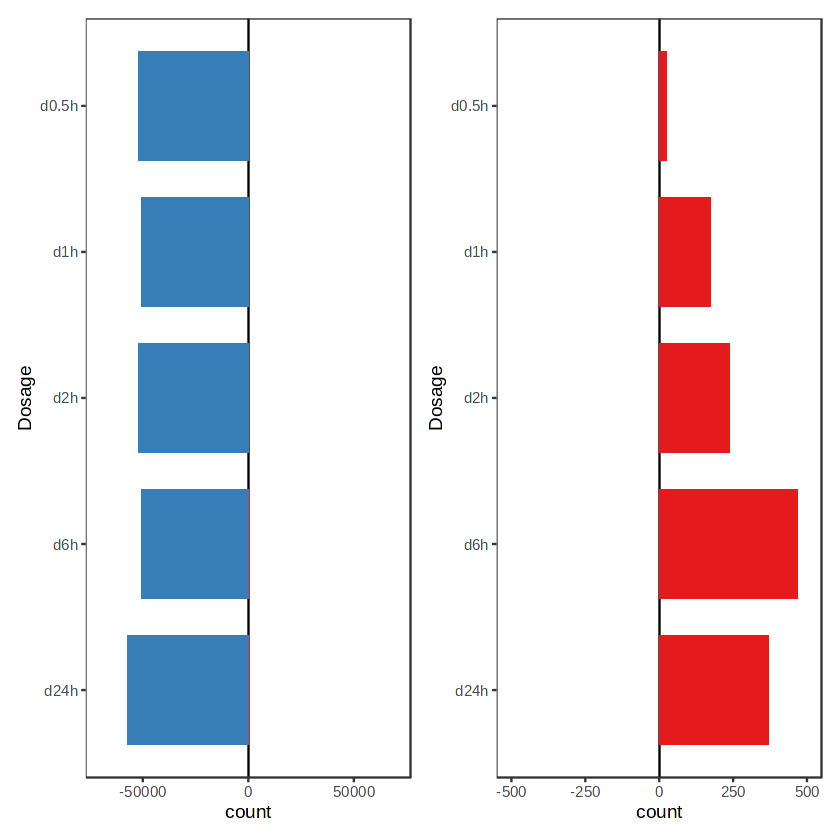

In [4]:
#BAFinh timecourse 

#generate barplots showing counts of DARs
p1 <- rbind(dar_0.5h %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d0.5h"=count) %>% t(), #make data frame of DAR counts (up, down, ns) by timepoint
      dar_1h %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d1h"=count) %>% t(),
      dar_2h %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d2h"=count) %>% t(),
      dar_6h %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d6h"=count) %>% t(),
      dar_24h %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d24h"=count) %>% t()) %>% 
    data.frame() %>% rownames_to_column("time") %>% select(!nc) %>% 
    pivot_longer(cols = c(up, down), names_to = "direction", values_to = "count") %>% #convert to tidy format for plotting
    mutate(count = ifelse(direction == "down", -(count), (count))) %>% #convert "down" counts to negative values (so that these values are plotted to the left of the y axis)
    ggplot(aes(y=factor(time, levels=rev(c("d0.5h", "d1h", "d2h", "d6h", "d24h"))),x=count,fill=direction)) + #generate plot
    theme_bw() + theme(panel.grid=element_blank()) + 
    geom_vline(xintercept=0) + 
    geom_col(width=.75, show.legend=F) + 
    coord_cartesian(xlim=c(-70000,70000)) +
    scale_x_continuous(breaks=c(-50000,0,50000)) + 
    scale_fill_manual(values = c("up" = brewer.pal(3, "Set1")[1], "down" = brewer.pal(3, "Set1")[2]))  + ylab("Dosage") 

#same as the above but using a limited x-axis to highlight gained DARs
p2 <- rbind(dar_0.5h %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d0.5h"=count) %>% t(), 
      dar_1h %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d1h"=count) %>% t(),
      dar_2h %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d2h"=count) %>% t(),
      dar_6h %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d6h"=count) %>% t(),
      dar_24h %>% group_by(change) %>% dplyr::summarize(count=n()) %>% column_to_rownames("change") %>% rename("d24h"=count) %>% t()) %>% 
    data.frame() %>% 
    rownames_to_column("time") %>% 
    select(!nc) %>% 
    pivot_longer(cols = c(up, down), names_to = "direction", values_to = "count") %>%
    mutate(count = ifelse(direction == "down", -(count), (count))) %>% 
    ggplot(aes(y=factor(time, levels=rev(c("d0.5h", "d1h", "d2h", "d6h", "d24h"))),x=count,fill=direction)) + 
    theme_bw() + theme(panel.grid=element_blank()) +
    geom_vline(xintercept=0) + 
    geom_col(width=.75, show.legend=F) + 
    xlim(-500,500) +
    scale_fill_manual(values = c("up" = brewer.pal(3, "Set1")[1], "down" = brewer.pal(3, "Set1")[2]))  + ylab("Dosage") 

timecourse_bar <- p1 | p2 
timecourse_bar

# Generate figure panel

Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_col()`).”


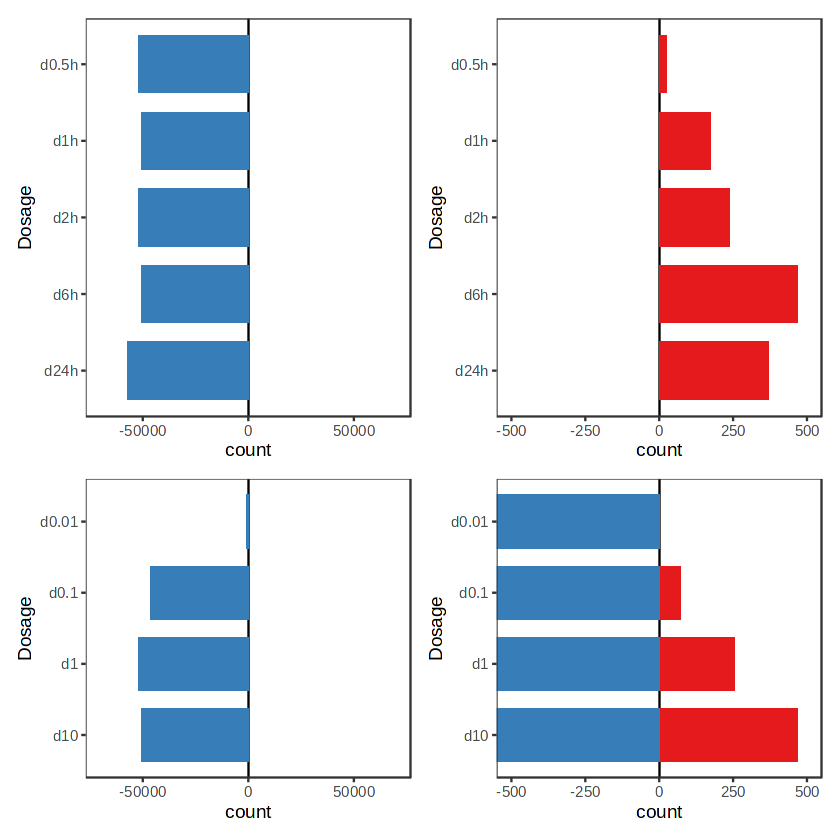

In [5]:
(timecourse_bar / titration_bar) + plot_layout(heights=c(1,.75))
suppressWarnings(ggsave("Panel_C.pdf", height=4, width=5))